# SENA - Analisis hasil fine-tuning dan threshold terpilih

**Workflow:** baca snapshot hasil -> bandingkan kesalahan -> baca keputusan A (0,95) -> tinjau pemeriksaan konfigurasi.

Pengguna memilih A (0,95). Hasil metrik berasal dari prediksi tersimpan; pemeriksaan Fusion memakai fixture buatan tanpa model. Tidak ada training, inferensi atau perubahan gold. Snapshot analisis lama tetap menyimpan keadaan sebelum pemilihan; konfigurasi terkini tersedia terpisah.


In [1]:
# Restore frozen code/data only; this cell does not run a model.
from pathlib import Path
import base64, hashlib, json, os, sys, zlib
WORK_ROOT = Path(os.environ.get("SLR09_NOTEBOOK_ROOT", '/content/slr09_sena_completed_analysis'))
SNAPSHOT = json.loads(zlib.decompress(base64.b64decode('eNrtfW2Tqsqy5l+5sT9P3Auoe44TcT+oCMppcImAwJcTCq3Ii+1ZaqtMzH+fJwtQQOzWtffZce/ERIfR3QpUVVbmk09mVaX/+zdv4QXv/n/s37eLf3gfyS5+P7z7/x7uP7a//a9/++399LEeD5TUEYJ4OR9uJpvexhPOF1WMDo7QPXjyOfZlK3qztXiZDA/OvBMsR3G6sNWDOmifx5vT38cD3LO1jrYQR+MQzwvHJzV0zqo4bFtij9PEKafxf+vgPUEL9UXlnpYSe3L34kvddCEPL5rhsD6oYq+lpaqgzd3ASYONlvYjTVYFNZx2NCPYOIkWu6Fzmhhe25lLG02UQjc0s/+TaWsiO23VMDknjTeurCRaGJ3dzXg/2PTW46326dtK6Frdi2v3P72tvnKTeO/aKrV91i55/1p64Msm3uv/T3YfvSdoH+6cD9g4t9puKUuXQjZ4xtG1dX6ZmAca25vRO6qzvM1fkxGbG1+WOD/r28bkLVxpSfrQGpauCZcCf1rKFufO9RX12xWslNqZs/nN2jclRTKH0ky/9YnulWdmR7J53TIic/PWu12vW27fkKy+Nay/H0wNXjHH6+w9e1buRydZzL2yzNgY3LnFxq2JlbYPjh2s0O+j29I/6HM1NIVyW/gs8JLObpn4Ky+ROHc2/n0sKjFky5ev80dKsJh3Vg6ugS6vPCH+Pbt2WHmea7vBUupuHFsPF6Rz9i5m7ab3/SLdwLOYHFWjV/685c7j7WIEvZGt0LEjmpvTW9g7V9qaSxfYCs3HpzfqZ2PAXC7m1tERSK96l8pY5xbnJXFoC+6nF3fRV42zBf4TbeyZziR84LSUT1twzre5J33WL7DL1E26Fzzj4vFdwbWVdDHvHjNdmx41wyNdzO4ZcTedhK5A/2NX6vK+nOmYGvYu2oY7qwPuPJGmJ0384Njr0ib97MAuf8I+f8frphesD/ERc7C1BeirbB28EZ47wByM9Is/N69t5nPF5OHaQey0SG+npDMcbCRufqb2ubT7sNHmZy4Tq2ULnRh2TfOLZ7uxl5CcrdV1jC/e92XfEiXwBGuPvsUP202sE3SguD9x5ufUvdnKYSnoMe6J30cMgxr7542UT3dkhb4cfy7jbnEP7OmMvuX3yNDpkVaSW/+C63h8voM9rnw5AM5pH0vhHNktYJVMz8vs0U2kvSeU5gb/L+aEe6y9HXQJY9KB0bBRvIDTsEngnNTlSD+bngGZXUgGhOnAri2zw4EizaX+DzOe3ukM5If5UahNocDgkr3V+3R0bOUC+935SYZxGrD0Ni/dE647kF3DhtC+dfIuhAPTS2nuYujEinyeIxxOSyE++iTHwRj23j36NM5BN12OxqeJRbLuBLBJyMHifJrvlnNSZ/BZsLm39Gscf2P+QvsJH7dbbvW0+v/0oIbrTb1ftfHC52qXJd9NVIZnveNEXJ+0dChoopmqYQR7jFrqTa/In4aLkbYq+28mp027JKcMV2CrF8iBZJlh070cImCS4M662rupXxa2G7/xmmLAj9i8ppphr1P6XzIiifReAMa1mC+S4/0SY2KYEg5PqhGYKslInLbsNMJ7kJP0cXxP4lPJnyWEDx7m51tcSj9OhEsTUe2oae+KS6Q7q0wm4AoS2QvN36rAWKYTo33R3gVz8ukleoM+4f2tAlsjG+6l4BdXvUQfw2WL3ctlvmuc3u6TQrIDzF2HfTZoY756mK8xPxF7NHdnyKN0/Q3bMSd72HhCsgbu7R1bS3O7gI9xeC01U81Q+YkRcapoXlRjfbMVwdq5QsB4gBsOb/fgBV25TGAHqqjinhLGyNalaIf6+l7iDHp0/mFw05o/ZxyK9xhuTTN7TYf76ud9yEXfXTEK/Sz5OpL5CXoSLmxwKKGd9xPjCVXottMp/a49F3NB8hlktqCmHmQwJZmeNWMswC5a2m2OctnCX2ZzwKupyatGdCaeAZ05afDZ12tvfpH6J00txZxJkjU1D1JNLhkvs/snzD+X84N2w/iiBXQjw/8ed7PRK7ZjLPHVT6N/sGVTAPfGGBi3xbwNvxv/6f5lfjF+yNQY4/nAj9RrQ2bcg/HLM0t5YtzT8zfjBjaOG3RDg30D3zY5phneSTPWbcw36SmnGpjHTU1e0Bf40H0+lhaei3kEIzci2AQwJVzX+1LCzCF397pe2++WedjU1MSZqUtG/ITei9E3eh+dn9B7zAVhQ+n35cuxt1XRS9U0Ao5i7OKQ7Jp7PPb19Vmrsg5GnR9G3JWsyJpYgzIeFtwQvpNiMzaOYdqkv64cX7mEmqrc92OlGI70b8pNDPIHXkcLp2ntPtKPYCmfCvlcoLcCjVMFZmKugf3OYx0PYWspzY2Hv5025rpV0vE7DowYDlz9fBcvFdhXiX1MaWYNA90ypbe7OIrspayzkYRZiYe62TGr71fknr0v3fpDvtfdWgwXwP8D8OXduwRu3/JTW/A/lzJxl+7en/NH8LOrvRU4chtDf1mWkVbTVXVQmc9TZQ7EXuXaiTi+XmuX9GB+enyPVvv/6/ac9vVaqYRD0v75Phpfjo9T11e5+LfnVGX0mkzW1fbC4RMyqvqzmk1V7aB+rTE+l2R0pzcudAJ8KfYz7g1uYmW8Vpy2Jzd+mMUhVvdIsQHi4Ri8lPSJX2aYBm6g3p7JuD14U0K6aAngwpzdIq5urZw5/8liuHK7o4KnTMFRTOD5GjbbaxO2TwzzFrMnWcxyfSbiO/BprhZrb3xwoixOzPrpj+IT+l4aW+/vN/xmvDH2R4hVwH/+INfjSxhzx/WAQTd7nWshxX9Oq8gDwI+JDkc+FnPWYXwrvD1rOZdCL+mCn0krwnSKLYh/O8I58BCfZfHKtzy/yEEQRy5hPZ7AfEgPcYkJXjxOb75EObm2krej1nM0sjHs/tD/DD8Abvq9H1iDh9Vf0Zdch8Y2EZ0L8/fiEGObttSan7xx3jXk5kD+Dl1LfDnF9Q/8oNU3Y31sWlZ/xplP+Pz1Nz4ffmrwLdeDX4LHrP184wfb4Fu110OuB+6M68MpcUhwZPAqcd3+V3M9TVSf4HomZDhtl39/M25mAxOjB3voYVw094/HDf7f0sj+0nVbS2F74EkPxt0Ha1T04VP85zT5Vu8bY4A61+MbOPvXes+4kglOPG4jbsb1Tush1zOmFAdj3CY4sUPXtrVTM881ou7E5qw54yffzr36Pc83pt/OPfoFbrZG7OoQ/wMuAuO+5rrg97hWXMOOI9jzmrBNeDR+6Afi2+kJnE9QU8SDBmK8m9/vZv0rySE5B05i7RnmlrlG5KoG1x1WeVsVJyq8MIrrefWybpXfnxhcZ6VbLosv8v74ZR+0TFyeyYxyPzblXIIV/EULXG/LcniUCx1Zh+VWW910MJdxaQxV3jE8a7PnuU0Nv87a69wJtu28wP9e55d37aVftse/zi+HX7dXwzpt+oSMwtoYjNozqrZQ9aPiWvgr+N9k8PW1bB3G6gZL+DL3qpMZjyu4iyqaLeIf4C+I15hfOJfijyuvbGif00ocB3pPbRRj4t7tflzhiiTzAtNvfpjlvR0hCMAd4xr/UwyYr8G7kp7helu7jdewhrFqSF3R4JWZbmpmFtc6t9xVrEg6r0hA1/z+EteJNXMGl2bz/gw2Psrujcr8NF/TsU5LQWPrXdqgyMnmn7WAp3avPA+bYh3qbg1EdI65Tm6WrT7iP373nliX7Bn9tLLelmi8L3cTN+6ytULHVoDL1XixnPcrrxnkOFy2jQ1hJuLR2toCW/e4+LK0y/G+jHsB5o/WtYC3XQH6wy2AXZ4QIJ5l8y5UbUOB/tJairQlXavcm63rHSv2eOXu0CUb3L8FnjtXPv3ErHN51hdHAKdLpPC98dk59wZ3An88g0fBj44vlXxUQmscXVpra7jf46prjgpidwXzp8RLuduyW/oHfFy6kGGvgzs5JdSvPPf/ifmKMS6MTVu58FWu4Odz36uNv4inOnRfYS8NfRu3K2uOlbiuYj/U3z309CfFUtAdzpmfGvy8kixpjUewoiwuNIu10NpcZrHTfRuEA9362CrPzzHoizFNq2vBzTFjkw7VckGVeKiunxhTmXMqlDP69PmyHqMtxImYb47WtTL7Ls+RBNvvXjDmDen2vR4456qOAecSWkPwY1pTLd9bcN0JYi1NXCO28U7gVIj9ppU1ZeAqrcWFzXIzuVr/rmsWD9qjmAXz71R+N+v6/f1adY39qtdNWMLaq8jCpX5xWU6sm0BnC/u76l+BU2ro3b8uv2Qrrb/IVu6xxmD48wdsaPyqDXF/jQ05L9uQWrW77/wIYgvzBT/C4tGOFlLMOETsZCLWUNsVHvaNb6ntHXnCt+TrG+G0BZ7UZjmap32Lk77mW4ZV+9xSnirjR0vBXd3ud/fAmW0ey2GeaI3Eqb+qe2macoNNuBFW5FPlkuX4hWHBGVznQDktbtnSg2U+hipOFX3VS3uCiHNOy7ZT2NMfsKEh1zTeK2e91wWu4pO3/gXP3t4wQ+94lDe9v+9cj0u/4WKt17nYtMrfKn2w7rCXZFjzI7SniPaVNfWf8hqpRvmodA2dpnUsj6vm80qyb/INxrjqt6451fhRe82+pME+J4NG22rAnjyH9Wt+5wJ9u3/9kt8Zdv4iv1PsQ7hMjNvehAf8obLORNiEsXzWcOOiNXLSL7AhXVf21TXHew335bH2NY9bzt1t7/j1saoDDVgpIf5MNOiRHizm7SweeYm7mUI9HvmOu2XrAmZlreAF7nZWX+NuHdXotaAXlwnF5vnvp7lbdf/j99ytyl2ej2nSMXf/mjZxmWr+ogFTq3Zcsbm6Lm+WtGeK2Yf+CczMco9GHf/zvkpd2n9WyLXg3ecSFz//ARuqcYFnbEj9a2xo9rIN1fZ+fM/dSnuZnuNu4l38c67280vuBk7zInejfLLRO1d+z57lbqrwGndT27/G3YAN6d3rV2xI+Gv80LDJD7X+gA0JL/uhKp/419mQ8XoOQTXM9CXuJjqt17ibxz/Nm5t8Qy12fIK78arocRNjytZoMded2rmAr/hcjVN9y+f4ynr183wO/YrO9devxD9VXfyX+aELzfuf6Ifq2P1EDmHY/mtyCFHnF+KftBrTf8fnhm318hKfu9A6dp1La8/7IujX8EVftAaH9Ggdqq0yzHcE9Wlf9Fourpa7e5rPTQzvUnulv5RD+GtsqEX7EWoxLPeHuFxovmhD41/zQ71X/FB97eTJeCh8aT3nxfxB72l/80rcs9xCnwfP2kTvRZv4lRhn+IvrNr2/IIf2eE3trg3o8bLmMzX48xfzZadf8xe9v9/28hZr7Ur8LkvsvEtlL0fZDpL87GV0kKYX7qQaaker7tngXDvgsrN2h08vUYLlpo/3/MC79MFt6eyU9NOZS8fxiP19cGb9gw8evLj09+5cCSDL41jWd/icX9K50EH/CB73s7KPJPELG6nuwalcUzpfVuHazBYre9SrHN1qvXJ9+WwM23cMGbnEP28+hs5MdID/wEVVoD3e1XWZTgzOlZ/71GPCjNva1BiY4bToLJQaeqkm1vx2vj7P5F1fO79vI7OnuPsTMsnnkc6nalKj/KC3fhLTfUfYQNbGZvwVz9gx+xwob7o5PqgirSOsK7LyZaudnRNTImfO/3Ts8RryO7rycA38iReD3u/jUR+6G8d4fzOWD/Qb1zE9ihaz/sWf88Fi0Ae378BuhmtXJn3RoDfDNZ2xY++3rD39duZt4Fcc/Nm607BX6Qgdv99L1LSnvXLuke1V2tG5wPw8K+27xHyvaa8h7bm8ZLsavbu2mnUtOqkhrjfWxKFaqlHeC8Lw6IPJJztPWOzVsE3IQb/cjyePj1cLIT7mcytPzbOhW9e99+V7gO0YC+4DF8nwcDDefJWXX2Q+fjONpMmbwc4bcLVzufH7KLsGXBTzuWb6skjiCzCCdGJP6wMefNZ4BIxJ/GA8wvuJdBiPlJ2ztegaivfwngf96ML3tKEz0dqlvT2QxVhWePilYFEd/7bwUbWzBpXY0yF8orOc1v0Zgsb9b5kdPnntd3rigB87Zy1FzEI5FHGKmHP9pJ6Qbk0F4HeLxY50Hm7wX19PdM7SmJ6kUfuRngAPLsAJYPJhR/ZP+vI+l34CSwp/BJ/Nn+B3NsAS+Bk99akmwzxG3N3558ImbGoTlqQO/JY/6P8T+sMvoCMMS27POS1G6Cd8mXsBZiU+9HOf6ZbtBouWhfmLKvjH9pdl8qnsYXzkTxrw5OF9j/zWF+dtyvrb7H9E2i/t0blTAbFZG7/bd2026ibtm/bobNI524M/vqhidU15Adx2s+s3ZmSN8DJMzhr+S/xWpAcueLi36f+Enm4yvaD+SkfoAZvvBTCEdGUs9cfmAL7G7gcLQYJ+0JkMC/pzjpcjKyT8gN7wy9lpjdjo6MF3IVb6p0Nyx3Pg4y7s3O/IxLPG6dvTPlMlnwm7HD7ymdCLABwuToFZiG3h7wRpT5joUb2AWZ/O6O/Ql/1Y5kkf8UL/yYcK5A8PAfWP9JP6vSC/Sv/Pce2mv0N/8RzrgOsQ7/d/Yn5adEacZAauGuD5m3dbI78bufDb7txN2FkO4moyH3itmLgbfPUU8og5h9kgfDUwATZGtQq2sMsO3t8u8Dzwu2ABn435YNiMfofQe5I5w2x37rM+LefFGGPYK9lXDB0/kL0eCbtxPeOLNHeYJ8pVPMDxB2fJvvH1jznCIyx/yl88sDeP10ST9mnD1tg+d+5pezPWdP9FY7mT+70vFXvjdcUYnlcWr/wwIu8eR/Kcni1AF5IceyNJhX2uHsqj0e4On8s5bAGYDB2gmCT3w9aFdGDRMhlngyw4siuqveHPdzxigZIuV/XXKumuznS3vZ61lB0wEjaqdKhWBau3sOnH0FA6i0Q2yTl2j56PWEPi6Jl4BuaNdAd9TA7wSVOy1/ObNOaftNmRbnKwWdqDHz2y2SP0OPaSqGQTmQxIj+F3ooyDwL8we6ZaGWfit1UfJVMsrfNOEh2g4xvY0U+yLS8h2+rHsP8W2d2S+QngFuxzscWYZz34+N56IceMD+ecCdiGubAtJkPIgfNhX4QLNC+ItS4ZHuJv+L98vgpfuKFaD+4F3DL1SJ7QKbJPnuEM/t4SVmQxH+EstRnTNdzNVg8Bq+8B3F22tICwY8nOag7zeerjWcHOHVmnvL+0hx/vSRHdg7FzBbeHLMBT2o987KPzA9/wtof2+4jjV8+5v8ThYOdpj9Ve0MDZweHS2rrvFxyOzrav6SxvO/OvnvAnc7jsWj6XhdQ151Zf+t7mO+QH0oyD5XFZi3Q0Bt7tmc6AM3Fkz8ShXFsLfNKP4Zkwdz2F/o2HO5NqXZAeLGXGr6BjZ55wnuri+Nm9GS8bMJ2gc3nQe8bL3uhvPBP3ASPg08hHU7vM5mE7hDfwISl8O57Fkd3R2ge/nHc6jrGv+6JbH5lf3QVkKxWfT/EF9DfngrAvZkdkXwWmcCVMKedc6jVsVvB3x8Xcjb1W5ew8dJYwPKY8IWJcvoj5/+y6IZgv7YPVzWhBf4wxrzEdH581UYcCaZGKGFOTnbMb6pCZFWuGG2hzKVTDOHFSHS+PdwT8GFPoM/wQ/JsqqJBr7zQRlY0bupCf01GTYVqtV3KOPb5cw6yCuUVdrONiq+V2N4Z/HHZUmc61T1P4iEA1/MgJg3giT6mWRRtxQkc13A184clBH+m8vJs4gmuYJyd1EVOOW24YhE46Rcwdx3TGomq/VjvzVTzLp9F5WIfVlRmW+yFMZPQlkRJV7G9U0Qqd0Cd+dkJcJmiyeoKPSJ3ExWdS4IbgeLIC/VLBqT3ooclpqQf5wJ7TddsV+5DntNaPrNbM21YL3IR8RCeldeusNhV4gqEEkHVHA5+A78fc0LPdWEtUXhWGbS2h2NA7O/Mp7ZNpq6KaTowI11Ofqe6bsgFPF1xZD1VZSnBdBVPJfh0hpvpM8NOHmPKX0NPTW7JLC56EPvMO5akSk1NDKXYM6MOcapCYiFH1jRP2hIkYxK7RjyYGcM5wOixfIdP5XroP/YB+OqESqKlJewNSp5ZbZG0n8e/gn2X5d9zEpDO7kLMfsXgFYwa3DyErjGfMaaEfq8lYcEU30cJ+pAluMjEgHWF8chITslIiLaQfhUbQhk5HtfjyE/Z+zGsiNeiignmVYpWdsexHauLw9HKA7ZphpmzshhU5yRBz0+M0AfMoo50UOiuPz2qih7APwUnjWJVdPAf2Eo4bapRd64Nd3JZ6dJI4r09GtT+cVBM9yFQKqNYf7DPSwINg52fX0BOqrwSrvKgy2SjVLlF514gR+4xhq+jrXMO1bqSKAeaK+KNa5TRJN8S14Nh5fjdUOVVQEjUM0F6QaIKVELeBrZ0nc2ACMMcNTbLRtiYPoVvAjjAGh6NzTZgH0YGc+5jzHvqhnjFHkZOqd3kA8jFLuRu4UjcF7lGNvvJZp7Thuv1SoNiB6SjnCOuGumjV+l7LeRe+9bwiX+1ez2Pe1RsDV+iCr+Vr39W1nsZ6YuUaSlSHzJPpOlovoDiSP7gUS+F/qpG2hE5ez98WdZfmZ+JRx7xW1911uQ+pxBJf96vDL+VTftarch3bF+MnjbXW6vXDeI/WBrMae/BJVrho9T8XbE9LURst50blWmxU21Gmem40ZraXt/Bxlbbg41Jf7gJztSCr09YJcO1N91sadCDmqA4kPQdctmOzPU7ELxpqshV1ulp+vJj7H6QXWQypcay2YGKRzuwwLo7atiknMD93wFfS+2exmI8Dv0FcFLN1xXcar81qCLzyDHAu4gjnFcaUYI6zuROsNvrF03lojI/p2MKmtaJrzdA7eREfBQf79G221wP+SftgMZeUz80l48LXtfBZV1ZnXXCa8SGvY/BZrpdCfJzVSxn0W9Qvxt9L87YcReu87ht0qt+C/D8Qy4eL+WHnD/g9q9m46VMcQjKOF3afuE9xhi6r3fZwfSn7PFs/Yn72E7p2dKxc5nG3yB2i7c4/6fzdUoR8t8rnO2IK6qs3srixpI2nM47xiIofk6XUy9faMEbe/Wrv0eO+CJA/eLyU40DOgfHczB929jRHwIrfXYqj5p2Tj9jM5IL+W8anyj7txGqTleojfpUHzeS+L/KciO+65VjmJht2hlXaU6xLfcz9NOESOP6O5XuW2z6PeM6YDYcHquVV9TV9VkejVE/xq3i4rGdUc4DVBBkP46F36bL1QPxmeZg38lsCH7wPqvmPtxbhsUK5rT30aUe12v6ceaMaAH3CDehxfn4TfB5cmnCD7btj+i5r0GH9w52BgyfxdkH2NujntW2nf05ftqW6kXKlhuG6qLMylq0z5mzvXfqIt12yr2p8iviDbNO5PKdD9Nue7rqD9X/+52//49+KSsab7eF9/XNx2Hxs/+F9bFeb9VPVjAnh3bnPKkdCmw55VLqlnWoZ4nO0EzGXVrXqrmVpkhl3Dd08S1Nel3SpKxu8spqZHVM3/dnU0hWDa1/vvXotWrkelVZhZ1ckKUXT9zv4Kl5UIO+l5P3uEOJfETePolgVxiKK+iZi+r0cZVU8Ywh2Je7IG3y6ibvK+lD0V79WL2GVMLOdm5tChm9Vrx3dqj5kKFdUfGa7TITq2DHj+zzKr2YVxdO6kjmo7TApVv0928qYfW0XJXme+/bMew9UkifQkKeqp1kGgbISY8pA5dUmSZb+ila1IUtufq0mrcRg6pe8j9eK0uhHwJCJsU2qXOKlWmhRVNF2wHhdUQdjH1Nlj7aTUETlsMp/E1kKHLBQsF0++x/sHgx1Ig55RGMdJ0HkGiICnRfegXbKlKrOYrxePj+EZDavSFYUSxZnDW3e7RtAtkxfO6spF0hT7jA1uJgyJIV+s8+MqGvaeF8fWlPd7LDMsw3dN/mr7IlRguUpO2I07xYx7PPO2SoF00qAUo2MrGCqmT5RliljGuOoOzA5a2ZF9321JKWPvvzQI3c1RX9sznLM4VmZcjH6ZRm6pazwuTiztJotdoJKdZPkVvGUVlqLDNPMPPczG+/0y17RbsHbyF3O/q7S63a3824Zt3LGo1rZ3JhyrjFMXTptKCKymTuck1iILE1EMlbgpBQRqhxeLW2uJVoyREQ6RdTrhq6hhZM5bFtcX5wEGjLXEQki4rwh6rUCaDUb0duwajsJneqLeFc2LxMR0XPqdDREkE6KKM9ABC3i+hRRvki7gNcnNVUpykV05ZxU9AVRaHsiuhGiv5ODKMkd/OHq5nvoT7xkVcPKlTKu1ageV+SsVGZxFbNWvfzRjpfKCsB9BfNrZW+GQ1tEFcSyEbF5Bd5G2g9jKA0y/evOYDca9FHRI8vA3xOD16GHMaseYfO+NDP9Md5XjFib0nszszth7RZsJKGM4/D5bBnX6ZtPZcto9/34YqcOsEdNNf7ZbJkCXDehg9bGMRCJi0rgGkwf2rQrH7p3mogWImA6QQQdMIJInSNaFxAtyw7sfcxphhJT5SE1JP2kXcnlFe+rjNNau7EbrhHxarQyF6iU9TGgn6ISavNpC5+hfTxXdGhX5kUNvQ7YOrAQfxvjFvpBWYlzvgM6dULnRLZUapdWLFbFavw3stp8XyHob4/07dC0wj01XZnmXzf1H9NoRzhrvJnSrJbNBs5K0HFXYTg84zHX3hcVKPmmTH+2e+HBZ7Sj581sWAHLd3E0fwY/EHVnBvUN+tvQb8JlYLE1a/hsCr0V9YaxmFRRiWt8HmxJkXRreoDNV3eDxZCLaTa87/+w4Bfg60RrGGv5M++q5BT4WI3A82+EyHyBaHDn/jTu5hXL9RXGPZmZLnyfnvtFHXhjibBrWzfj0UzSiQsaJvwP2v5hsGz5teoL9FI60co6i/S312pg8IPx3qFIFhyMquV7jINOj2oxZ7dKUNWK/sU3T8zzzzd8oNEJ1IzD3u7futlqsNXdgplfwM2an2Pn18347LpBrR+IUClz5bYs4lH5anN1LEvyqzMekdA5fpv7PMNPiuxm9Kzxlav483O9Ik9IO7BdoXsBh6DI88AyMYm0omj0fdZUtb+8Wzw7eUT+zp8rB/C+6/hYhHPD9g/afZfLcgdeGRacGtyk5dhxyr6NxLZ2FLU03B8v7T7xHMrU7F2WiemyXUC2IFF0xlb6WOU2+IzlXPoJ/K7toq5n8qzjQuh8+mw3b8BlO4iJc1AGzqIVhQvbhQDcYjuZs52wRT9Y1fySfMo6V832CVTB//z53pRhej2buGGcO+N8dEoh9tiuNcoASSfKFPpJUzs67XCLfegg9BFzRivYLBtM3ybwT1aFX+qy1byiD5Xs0pdZMtotkmWkbnJkdsNiiiWteFJcAj27fitCQisjiAvK47uPNg/Bz/d98BH7FGsefi68wz/wvhftnwo6S0I8lIO8tzmCEpYS1zj8naeVqgHo/3tBZN5f2q5f9KMcJFFgMzdTIhUayK4zp60kVuiAGIMIBxOZSng6Z02wYrYklvohSIGAYOni0PJQCIM2hiDXdOxiDQKtJ65RpGKK4NKnNGJuFCUHQEEiwMxrEemrf91HniJqlUlqNYVEaax8axc5hmzcYnVbRfMy+LSyJbp+9K8KQBlgXI81UTpxLqUsDVQtXU19Ug3eR4CHoIbXQE5j8Rb0deHM2VYiOOXmsnvj5Hac09nGleM5DV/5UQbH+H2kl47YSbTFlYAhIsDEcyrHGwlwIbv7dPsvpRelNHfgjOTYKTtueRrXSio1bGPgv5qDhrGWQJ3ZUkBJjowgHvzqdsjrUYzNe+W4bdMSDVuypa/N6VAqnb4m51rKbn7+ZFv0QbQ92q7Adxv70Kwzr6VDG3W5tq2vWZcrZVz/vxyvcixtyZH+xr7mYlJdGm7cTlct1658TSRq8r7a1bYeWBOZP/+w+K4IUm6YXCzPTK3PSGuM97iOzIKYSJPGjSU/v52Lu37RVjAKomuOGQSiS2l/kGMEgiBBlSObV2xrHuuLaWzMqXm3HfK/AT78d5Pl+RlZqo/82abhq6y+0etXfNadPf+XwgiyQWtk8Iprc+7M4PiVyVmTqdW1Z0NrUiR9ssQCgtChNNDNMyWaZD2yZuY3SyqV+S4liKecRAsYCHLjFX09IAL4jBdY3R9GdEZfOj8Q5I7wnoT2VcYPEQwDL0Sb03CNq84o0cXpklUJfp8ZM68QNzEif2UNg5luaWME3kNKWM8ouB7WttP/smxv7cCfyTq4AeHbL7RT3voGmzuv7mwn59vwjdAp60LJ3yXx3evW5RiyC6Sr/GIdc31WdVNfWZCvZVpGLvOJblmzKeaY5gXznMk2vvLZ5mX8u6+DU75dqm8KCMHdLuxr2RCEs69MHFlFUp8dxbwmNATaQugfly3ie9pXX3m3WYxoe/4t8AJfuy5BF0E32zYg1OOEOm59EcgDE2mrEy0h4xmflLTNtxMU1zbJ6IVgWeJpkYMwmMpcuDbbzksLP4E3QiDdcqtbaLbc33/7P/8XBWo3bA==')))
EXPECTED = {'cached/sena_completed.json': '73499d8c170c95ffd1ed693290d75c8a03a2271e3807e8fa46e50f4aff3d5691', 'cached/integration_config.json': 'dbee386a46cae545ca565ca8c38617ee640c7cf86b42b71b9ca14e03684fdfe3', 'cached/threshold_contract_checks.json': 'dc822f37b41b17448123364c3fdc2efa6e42f6a60593bdba8b13d32405d22839'}
for relative, value in SNAPSHOT.items():
    raw = base64.b64decode(value)
    if hashlib.sha256(raw).hexdigest() != EXPECTED[relative]:
        raise ValueError("Frozen snapshot differs: " + relative)
    rel = Path(relative)
    if rel.is_absolute() or ".." in rel.parts:
        raise ValueError("Invalid snapshot path")
    target = WORK_ROOT / rel
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_bytes(raw)
sys.path.insert(0, str(WORK_ROOT / "code"))
print("Snapshot restored:", len(SNAPSHOT), "files.")


Snapshot restored: 3 files.


In [2]:
analysis = json.loads((WORK_ROOT / "cached/sena_completed.json").read_text())
print("Run:", analysis["run_id"])
print("Baseline:", analysis["baseline_metrics"]["macro_f1_all_five_classes"])
print("Fine-tune:", analysis["finetuned_metrics"]["macro_f1_all_five_classes"])
print("Perubahan:", analysis["prediction_changes"])
for row in analysis["cutoff_comparison"]:
    if row["threshold"] in [.9, .95, .99]:
        print("Cutoff", row["threshold"], "flag", row["below_threshold_uncertain"], "error flagged", row["errors_below_threshold"], "error above", row["errors_at_or_above"])
integration = json.loads((WORK_ROOT / "cached/integration_config.json").read_text())
contract_checks = json.loads((WORK_ROOT / "cached/threshold_contract_checks.json").read_text())
print("Dipilih pengguna:", integration["selected_option"], integration["confidence_threshold"])
print("Referensi:", integration["calibration_reference"])
print("Pemeriksaan kontrak tanpa model:", len(contract_checks["checks"]), "lulus:", contract_checks["all_passed"])
print("Human Verification wajib:", integration["rules"]["human_verification_always_required"])
print("Diterapkan pada aplikasi:", integration["production_deployed"])


Run: 20261018T044447_926664Z
Baseline: 0.6575353599405218
Fine-tune: 0.8807164532997971
Perubahan: {'IMPROVED': 184, 'STILL_CORRECT': 362, 'REGRESSED': 35, 'STILL_WRONG': 39}
Cutoff 0.9 flag 102 error flagged 38 error above 36
Cutoff 0.95 flag 153 error flagged 51 error above 23
Cutoff 0.99 flag 437 error flagged 72 error above 2
Dipilih pengguna: A 0.95
Referensi: SLR09_SENA_20261018T044447_926664Z:reviewed_validation620:cutoff_0.95
Pemeriksaan kontrak tanpa model: 9 lulus: True
Human Verification wajib: True
Diterapkan pada aplikasi: False


## Contoh kesalahan yang tetap dilaporkan

Acuan di bawah mengikuti review final, tidak disunting agar cocok dengan prediksi.


In [3]:
for row in analysis["examples"]:
    print(row["id"], "gold:", row["gold"], "prediksi:", row["new_prediction"], "confidence:", row["new_confidence"])
    print(row["text"])
    print()


KEC-01395 gold: NON_EVENT prediksi: ACCIDENT confidence: 0.9926267266273499
korban tewas kecelakaan selama mudik lebaran di sumsel naik

KEB-00598 gold: NON_EVENT prediksi: FIRE confidence: 0.9902331829071045
damkar banda aceh : penyebab kebakaran di rumah tangga dan cara penanggulangan nya

BAN-01074 gold: NON_EVENT prediksi: FLOOD confidence: 0.9835461378097534
cegah banjir dan longsor warga tanam ribuan batang pohon di gunung buthak

GEM-01398 gold: NON_EVENT prediksi: EARTHQUAKE confidence: 0.9827017188072205
dari sekian banyak korban gempa bumi tsunamibanjirdan pesawat jatuhhanya korban php yang enggak di evakuasi

KEC-00351 gold: ACCIDENT prediksi: NON_EVENT confidence: 0.9818987250328064
sehabis baca salah satu artikel mengenai kecelakaan di tanjakan emen itu semakin khawatir kalau bystander effect di masyarakat kita semakin tinggi ya gila saja orang kecelakaan begitu malah sibuk direkamin bukan dibantuin

GEM-01229 gold: ACCIDENT prediksi: EARTHQUAKE confidence: 0.9756837487220

## Confusion matrix dari run Colab

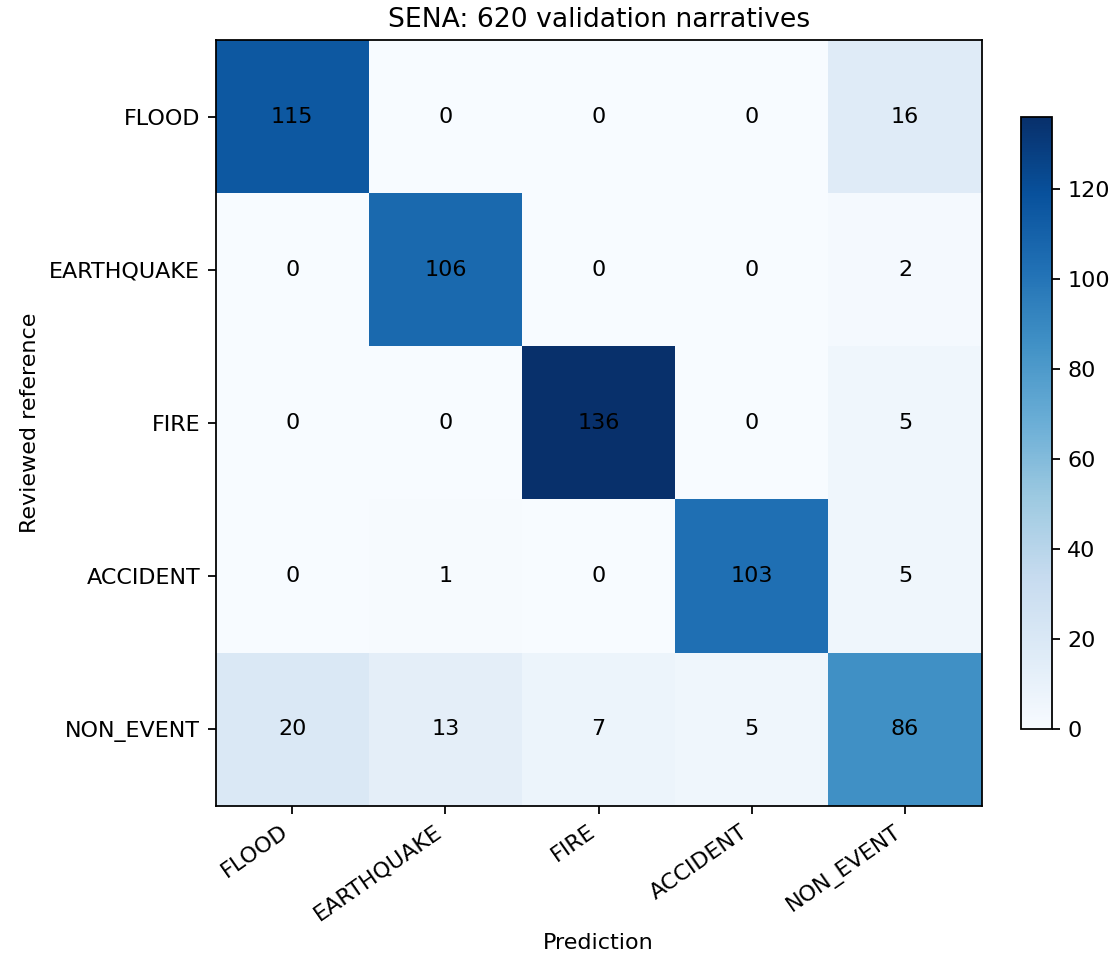


## Kurva dari run Colab

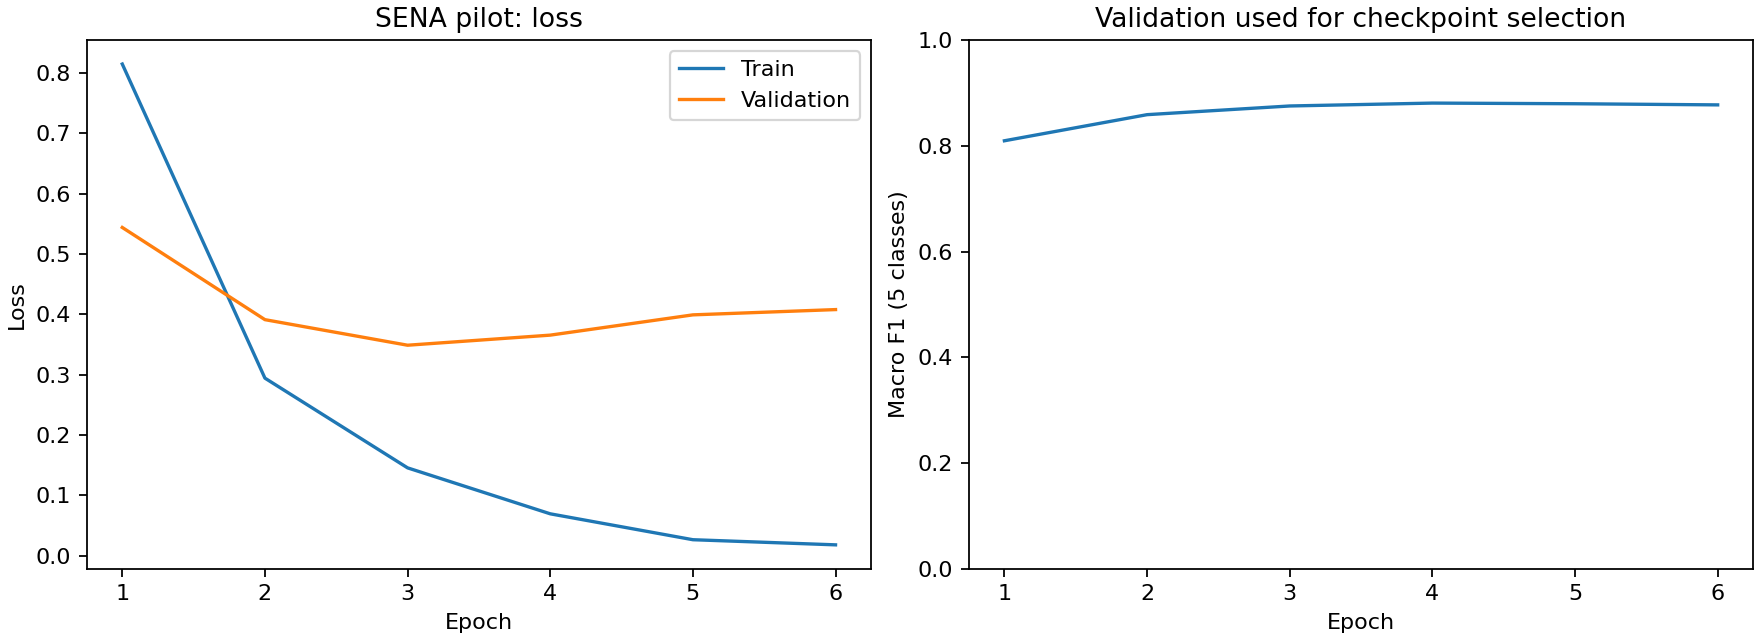


## Kode analisis lengkap

File yang sama tersedia pada code/analyze_sena_completed_run.py. Reproduksi dari paket diekstrak bersifat opsional dan tidak memerlukan bobot.

```python
"""Analyze the completed SENA run from saved predictions only.

The module does not load model weights, train, or run neural inference.
It preserves the reviewed labels and proposes, rather than selects, cutoffs.
"""
from __future__ import annotations

import argparse
import csv
import hashlib
import json
import math
from collections import Counter
from pathlib import Path
from zipfile import ZipFile

RUN_ID = "20261018T044447_926664Z"
EXPECTED_ZIP_SHA256 = "0077365fac8b70d4c624958bbcef60978aab41cf50978bd78f8154c9bdbf691f"


def dump(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def write_csv(path, rows):
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)


def analyze(root: Path, run_zip: Path | None = None) -> dict:
    root = Path(root)
    run_zip = Path(run_zip) if run_zip else root / "sources" / f"SLR09_SENA_Hasil_FineTune_{RUN_ID}.zip"
    if hashlib.sha256(run_zip.read_bytes()).hexdigest() != EXPECTED_ZIP_SHA256:
        raise ValueError("Completed SENA report archive differs")
    baseline_path = root / "results/sena_reviewed_620/scored_rows.json"
    baseline = {r["id"]: r for r in json.loads(baseline_path.read_text())}
    refs_path = root / "data/sena_validation_reviewed.jsonl"
    refs = {r["id"]: r for r in [json.loads(line) for line in refs_path.read_text().splitlines() if line.strip()]}
    destination = root / "results" / ("sena_finetune_" + RUN_ID)
    destination.mkdir(parents=True, exist_ok=True)
    with ZipFile(run_zip) as archive:
        if archive.testzip() is not None: raise ValueError("Report ZIP CRC error")
        for entry in archive.infolist():
            relative = Path(entry.filename)
            if relative.is_absolute() or ".." in relative.parts: raise ValueError("Invalid report path")
            if not entry.is_dir():
                target = destination / relative
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(entry.filename))
        read_json = lambda name: json.loads(archive.read(name))
        state = read_json("run_state.json")
        comparison = read_json("comparison.json")
        metrics = read_json("finetuned_validation_metrics.json")
        cutoffs = read_json("cutoff_analysis.json")["rows"]
        history = read_json("training_log_history.json")
        export = read_json("model_export_manifest.json")
        inputs = read_json("input_manifest.json")
        rows = [json.loads(line) for line in archive.read("finetuned_validation_predictions.jsonl").decode().splitlines() if line.strip()]
    assert state["run_id"] == RUN_ID and state["status"] == "SUCCEEDED"
    assert state["training_completed"] and state["model_exported"]
    assert not state["baseline_neural_inference_repeated"]
    assert not state["production_model_selected"] and not state["production_threshold_selected"]
    assert len(rows) == len(baseline) == len(refs) == 620
    assert len({r["id"] for r in rows}) == 620 and {r["id"] for r in rows} == set(baseline) == set(refs)
    checks = []
    for relative, expected in inputs["sha256"].items():
        assert hashlib.sha256((root / relative).read_bytes()).hexdigest() == expected
        checks.append({"check": relative + ": frozen input SHA-256", "passed": True})
    transitions = []
    for row in rows:
        rid = row["id"]; old = baseline[rid]; ref = refs[rid]
        assert row["text"] == old["text"] == ref["text"] and row["gold"] == old["gold"] == ref["final"]
        probabilities = row["probabilities"]
        assert set(probabilities) == set(metrics["labels"])
        assert all(math.isfinite(v) and 0 <= v <= 1 for v in probabilities.values())
        assert abs(sum(probabilities.values()) - 1) < 2e-5
        assert row["prediction"] == max(probabilities, key=probabilities.get)
        assert math.isclose(row["confidence"], probabilities[row["prediction"]], abs_tol=1e-6)
        old_correct = old["prediction"] == row["gold"]
        new_correct = row["prediction"] == row["gold"]
        change = ("STILL_CORRECT" if old_correct else "IMPROVED") if new_correct else ("REGRESSED" if old_correct else "STILL_WRONG")
        kind = "CORRECT" if new_correct else ("FALSE_NON_EVENT" if row["prediction"] == "NON_EVENT" else
            ("FALSE_EVENT" if row["gold"] == "NON_EVENT" else "WRONG_EVENT_TYPE"))
        transitions.append({"id": rid, "text": row["text"], "gold": row["gold"],
            "baseline_prediction": old["prediction"], "new_prediction": row["prediction"],
            "baseline_confidence": old["confidence"], "new_confidence": row["confidence"],
            "change": change, "new_error_kind": kind, "review_note": ref["note"]})
    checks.append({"check": "all 620 IDs/texts/gold/argmax/confidence/probabilities", "passed": True})
    counts = dict(Counter(row["change"] for row in transitions))
    assert counts["STILL_CORRECT"] + counts["IMPROVED"] == metrics["correct"]
    assert counts["REGRESSED"] + counts["STILL_WRONG"] == metrics["incorrect"]
    extended = []
    for cutoff in cutoffs:
        threshold = cutoff["threshold"]
        low = [r for r in rows if r["confidence"] < threshold]
        high = [r for r in rows if r["confidence"] >= threshold]
        wrong_high = [r for r in high if r["gold"] != r["prediction"]]
        wrong_low = [r for r in low if r["gold"] != r["prediction"]]
        assert len(low) == cutoff["below_threshold_uncertain"]
        assert len(high) == cutoff["at_or_above_threshold"]
        assert len(wrong_low) == cutoff["errors_below_threshold"]
        assert len(wrong_high) == cutoff["errors_at_or_above"]
        assert len(wrong_low) + len(wrong_high) == 74
        extended.append({**cutoff, "flagged_rate": len(low) / len(rows),
            "correct_predictions_also_flagged": len(low) - len(wrong_low),
            "false_event_at_or_above": sum(r["gold"] == "NON_EVENT" for r in wrong_high),
            "wrong_event_type_at_or_above": sum(r["gold"] != "NON_EVENT" and r["prediction"] != "NON_EVENT" for r in wrong_high)})
    checks.append({"check": "all nine cutoff partitions match the original report", "passed": True})
    evaluation_epochs = [r for r in history if "eval_macro_f1" in r]
    best_epoch = max(evaluation_epochs, key=lambda r: r["eval_macro_f1"])
    assert math.isclose(best_epoch["eval_macro_f1"], state["best_validation_macro_f1"], abs_tol=1e-12)
    assert math.isclose(metrics["macro_f1_all_five_classes"], best_epoch["eval_macro_f1"], abs_tol=1e-12)
    checks.append({"check": "selected checkpoint metric equals saved prediction metric", "passed": True})
    example_ids = ["KEC-01395", "KEB-00598", "BAN-01074", "GEM-01398", "KEC-00351", "GEM-01229"]
    examples = [next(r for r in transitions if r["id"] == rid) for rid in example_ids]
    result = {"schema": "slr09-completed-sena-analysis-0.1", "run_id": RUN_ID,
        "run_report_sha256": EXPECTED_ZIP_SHA256, "source_report_files": 17,
        "state": state, "baseline_metrics": comparison["baseline_reused_without_neural_rerun"],
        "finetuned_metrics": metrics, "prediction_changes": counts,
        "best_epoch": best_epoch["epoch"], "best_step": best_epoch["step"],
        "epochs_completed": state["epochs_completed"], "optimizer_steps": state["optimizer_steps"],
        "cutoff_comparison": extended, "examples": examples, "model_export_manifest": export,
        "proposed_recommended_cutoff": 0.95, "alternative_cutoff": 0.90,
        "confidence_threshold_selected": None, "threshold_activated": False,
        "validation_used_for_checkpoint_selection": True, "independent_test": False,
        "historical_sena_training_split_identity_verified": False,
        "model_weights_directly_read_in_this_analysis": False,
        "new_training_executed_in_this_analysis": False,
        "new_neural_inference_executed_in_this_analysis": False,
        "previous_attachment_check": "Accuracy/F1/per-class/confusion matrix were independently checked with scikit-learn on receipt.",
        "checks": checks}
    dump(destination / "completed_run_analysis.json", result)
    write_csv(destination / "prediction_transitions.csv", transitions)
    write_csv(destination / "threshold_comparison.csv", extended)
    write_csv(destination / "error_examples.csv", examples)
    return result


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=Path(__file__).resolve().parents[1])
    parser.add_argument("--run-zip", type=Path)
    arguments = parser.parse_args()
    result = analyze(arguments.root, arguments.run_zip)
    print(json.dumps({"run_id": result["run_id"], "changes": result["prediction_changes"],
        "best_epoch": result["best_epoch"], "checks_passed": len(result["checks"]),
        "threshold_selected": None, "training_or_neural_inference_executed_here": False}, indent=2))

```


## Kode pemeriksaan konfigurasi lengkap

File yang sama tersedia pada code/verify_selected_fusion_config.py. Pemeriksaan ini telah selesai; menjalankannya kembali bersifat opsional.

```python
"""Check the selected configuration with synthetic Fusion fixtures, without models.

These checks establish configuration and boundary behavior only. They neither
re-evaluate model accuracy nor verify enforcement by a deployed backend.
"""
from __future__ import annotations

import argparse
import hashlib
import json
import sys
from pathlib import Path


def load(path):
    return json.loads(path.read_text(encoding="utf-8"))


def verify(root):
    root = Path(root)
    config_path = root / "config/SLR09_Konfigurasi_Integrasi_v0.1.json"
    config = load(config_path)
    decision = load(root / "config/threshold_decision.json")
    options = load(root / "config/threshold_options.json")
    models = load(root / "config/model_candidates.json")
    analysis = load(root / "results" / ("sena_finetune_" + config["reference_run_id"])
                    / "completed_run_analysis.json")
    selected = next(o for o in options["options"] if o["option"] == config["selected_option"])
    assert decision["decision_source"] == "EXPLICIT_USER_INSTRUCTION"
    assert decision["scope"] == "CANDIDATE_INTEGRATION_CONFIGURATION"
    assert config["selected_option"] == options["selected_option"] == decision["selected_option"] == "A"
    assert (config["confidence_threshold"] == options["confidence_threshold"]
            == decision["confidence_threshold"] == models["threshold_selected"] == .95)
    assert config["calibration_reference"] == options["calibration_reference"] == selected["calibration_reference"]
    assert config["sena"] == models["sena"] and config["nara"] == models["nara"]
    assert config["sena"]["weights_sha256"] == decision["sena_weights_sha256"] == options["sena_weights_sha256"]
    assert config["sena"]["weights_sha256"] == analysis["model_export_manifest"]["files_sha256"]["model.safetensors"]
    source_report = root / "sources" / ("SLR09_SENA_Hasil_FineTune_" + config["reference_run_id"] + ".zip")
    assert (hashlib.sha256(source_report.read_bytes()).hexdigest()
            == config["reference_report_sha256"] == decision["reference_report_sha256"])
    assert not options["activated"] and not config["production_deployed"]
    assert not config["production_model_selected"] and not models["production_model_selected"]
    assert not config["quality_acceptance_approved"] and not config["probability_calibration_fitted"]
    assert not config["target_vm_loading_and_joint_new_model_inference_verified"]
    assert all(config["rules"].values())
    assert config["rules"]["human_verification_always_required"]

    adapter_directory = str(root / "code/active_nara_adapter")
    sys.path.insert(0, adapter_directory)
    try:
        from silar_ai_adapter import (
            ADAPTER_VERSION, FUSION_VERSION, EVENT_CATEGORIES, NARA_LABELS,
            CalibrationRequiredError, adapt_legacy_ai_output, fuse_for_silar,
        )
        assert config["adapter_version"] == ADAPTER_VERSION
        assert config["fusion_version"] == FUSION_VERSION

        def adapted_fixture(category, confidence, conflicting_nara_category=False):
            # Deliberately synthetic: these values are not model predictions.
            text = "Banjir" if conflicting_nara_category else "Laporan"
            spans = {role: [] for role in NARA_LABELS if role != "O"}
            role = "FLOOD-EVENT" if conflicting_nara_category else "O"
            if conflicting_nara_category:
                spans[role] = [{"role": role, "text": text, "mean_confidence": .99}]
            raw = {"report_text": text,
                "event_classifier": {"label": category, "confidence": confidence,
                    "probabilities": {label: confidence if label == category else (1-confidence)/4
                                      for label in EVENT_CATEGORIES}},
                "srl_token_predictions": [{"original": text, "token": text.lower(),
                    "start": 0, "end": len(text), "label": role, "confidence": .99}],
                "srl_spans": spans}
            return adapt_legacy_ai_output(raw, narrative_id="SYNTHETIC-CONTRACT-ONLY",
                sena_model_version="SENA-" + config["sena"]["run_id"],
                nara_model_version="NARA-" + config["nara"]["run_id"])

        checks = []
        for category in ("FIRE", "NON_EVENT"):
            for confidence in (.949, .950, .951):
                fixture = adapted_fixture(category, confidence)
                result = fuse_for_silar(fixture,
                    confidence_threshold=config["confidence_threshold"],
                    calibration_reference=config["calibration_reference"])
                fields = result["incident_card_version_fields"]
                expected_reasons = ["LOW_CLASSIFICATION_CONFIDENCE"] if confidence < .95 else []
                assert fields["uncertain_reasons"] == expected_reasons
                assert fields["uncertain"] is bool(expected_reasons)
                assert result["integration_signals"]["blocked_by_non_event"] is (category == "NON_EVENT")
                assert fields["data"]["event_type"] == (None if category == "NON_EVENT" else category)
                assert fields["data"]["location_text"] is None and fields["data"]["time_text"] is None
                assert fields["data"]["occurred_at"] is None
                assert all(fields["data"][name] == [] for name in
                           ("involved_parties", "impacts", "victims", "affected_objects"))
                assert result["fusion_metadata"]["calibration_reference"] == config["calibration_reference"]
                checks.append({"case": f"{category}_{confidence:.3f}", "confidence": confidence,
                    "uncertain": fields["uncertain"], "uncertain_reasons": fields["uncertain_reasons"],
                    "blocked_by_non_event": result["integration_signals"]["blocked_by_non_event"],
                    "empty_extraction_alone_adds_no_uncertain_reason": True, "passed": True})

        conflict_fixture = adapted_fixture("FIRE", .95, conflicting_nara_category=True)
        conflict_result = fuse_for_silar(conflict_fixture,
            confidence_threshold=config["confidence_threshold"],
            calibration_reference=config["calibration_reference"])
        assert conflict_result["incident_card_version_fields"]["data"]["event_type"] == "FIRE"
        checks.append({"case": "CATEGORY_FROM_SENA_WHEN_NARA_EVENT_LABEL_DIFFERS", "passed": True,
            "scope": "CATEGORY_PRECEDENCE_ONLY_NOT_GENERAL_SEMANTIC_CONFLICT_DETECTION"})

        for threshold, reference, name in [
            (None, config["calibration_reference"], "MISSING_THRESHOLD_REJECTED"),
            (config["confidence_threshold"], None, "MISSING_REFERENCE_REJECTED"),
        ]:
            try:
                fuse_for_silar(conflict_fixture, confidence_threshold=threshold, calibration_reference=reference)
            except CalibrationRequiredError:
                checks.append({"case": name, "passed": True})
            else:
                raise AssertionError(name)
    finally:
        sys.path.remove(adapter_directory)

    result = {"schema": "slr09-selected-threshold-contract-checks-0.1",
        "selected_option": config["selected_option"], "confidence_threshold": config["confidence_threshold"],
        "calibration_reference": config["calibration_reference"],
        "configuration_sha256": hashlib.sha256(config_path.read_bytes()).hexdigest(),
        "configuration_identity_consistent": True, "checks": checks, "all_passed": True,
        "fixture_source": "SYNTHETIC_CONTROLLED_VALUES_NOT_NEURAL_PREDICTIONS",
        "training_executed": False, "neural_inference_executed": False,
        "prior_nara_evaluation_or_adapter_diagnostic_repeated": False,
        "human_verification_required_in_configuration": True,
        "human_verification_backend_enforcement_verified": False,
        "production_deployed": False, "quality_acceptance_approved": False}
    evidence_path = root / "evidence/selected_threshold_contract_checks.json"
    evidence_path.write_text(json.dumps(result, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    return result


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--root", type=Path, default=Path(__file__).resolve().parents[1])
    arguments = parser.parse_args()
    result = verify(arguments.root)
    print(json.dumps({"selected_option": result["selected_option"],
        "confidence_threshold": result["confidence_threshold"], "checks_passed": len(result["checks"]),
        "all_passed": result["all_passed"], "neural_inference_executed": False}, indent=2))

```
